In [2]:
import pandas as pd
dataset=pd.read_csv("50_Startups.csv")

In [3]:
dataset=pd.get_dummies(dataset,drop_first=True)
dataset.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit',
       'State_Florida', 'State_New York'],
      dtype='str')

In [4]:
independent=dataset[['R&D Spend', 'Administration', 'Marketing Spend','State_Florida', 'State_New York']]
dependent=dataset[["Profit"]]

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent, dependent, test_size=0.30,random_state=0)


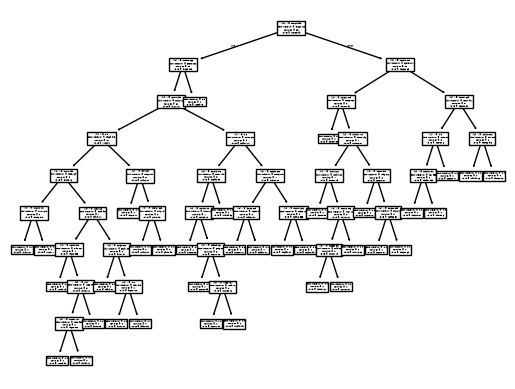

0.7144161718413736

In [13]:
#https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
from sklearn.tree import DecisionTreeRegressor # this is the procedure for the decision tree
regressor=DecisionTreeRegressor(criterion='absolute_error', splitter='best', max_features='sqrt', random_state=42) # to get the suitable model we can pass the parameters (squared_error,absolute_error,poisson)
regressor=regressor.fit(X_train,y_train)

import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(regressor)
plt.show()

y_pred=regressor.predict(X_test)
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)
r_score

In [ ]:
import pickle
filename="finalized_model_Mul_linear.sav"
pickle.dump(regressor,open(filename,'wb'))

In [ ]:
loaded_model=pickle.load(open("finalized_model_Mul_linear.sav",'rb'))
result=loaded_model.predict([[1000,2000,3000,1,0]])

In [ ]:
result